
████████████████████████████████████████████████████████████
  MLP-BASED INTRUSION DETECTION — CICIDS2017
  Following: Cherf, Lemouari & Boulaiche (2025)
████████████████████████████████████████████████████████████

STEP 1: LOADING CICIDS2017 DATASET
  Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
  Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
  Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
  Loading: Monday-WorkingHours.pcap_ISCX.csv
  Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
  Loading: Tuesday-WorkingHours.pcap_ISCX.csv
  Loading: Wednesday-workingHours.pcap_ISCX.csv

  ✓ Total records loaded : 2,830,743
  ✓ Total features       : 79

STEP 2: PREPROCESSING
  Label column: 'Label'
  Removed 2,867 rows with null/inf values
  Sampled to 49,995 rows (CPU-friendly)

  ⚠ Dropping 3 rare class(es) with <10 samples:
    - Heartbleed (1 sample(s))
    - Infiltration

Model: "sequential_51"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 50)                  │           2,150 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 12)                  │             612 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,762 (10.79 KB)

 Trainable params: 2,762 (10.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
108/108 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7034 - loss: 1.3001 - val_accuracy: 0.8748 - val_loss: 0.5065
Epoch 2/100
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8923 - loss: 0.3952 - val_accuracy: 0.9051 - val_loss: 0.3318
Epoch 3/100
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9106 - loss: 0.2946 - val_accuracy: 0.9216 - val_loss: 0.2744
Epoch 4/100
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9284 - loss: 0.2518 - val_accuracy: 0.9321 - val_loss: 0.2444
Epoch 5/100
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9349 - loss: 0.2273 - val_accuracy: 0.9353 - val_loss: 0.2255
Epoch 6/100
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9376 - loss: 0.2106 - val_accuracy: 0.9373 - val_loss: 0.2119
Epoch 7/100
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9401 - loss: 0.1982 - val_accuracy: 0.9409 - val_loss: 0.2018
Epoch 8/100
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9416 - loss: 0.1886 - val_a

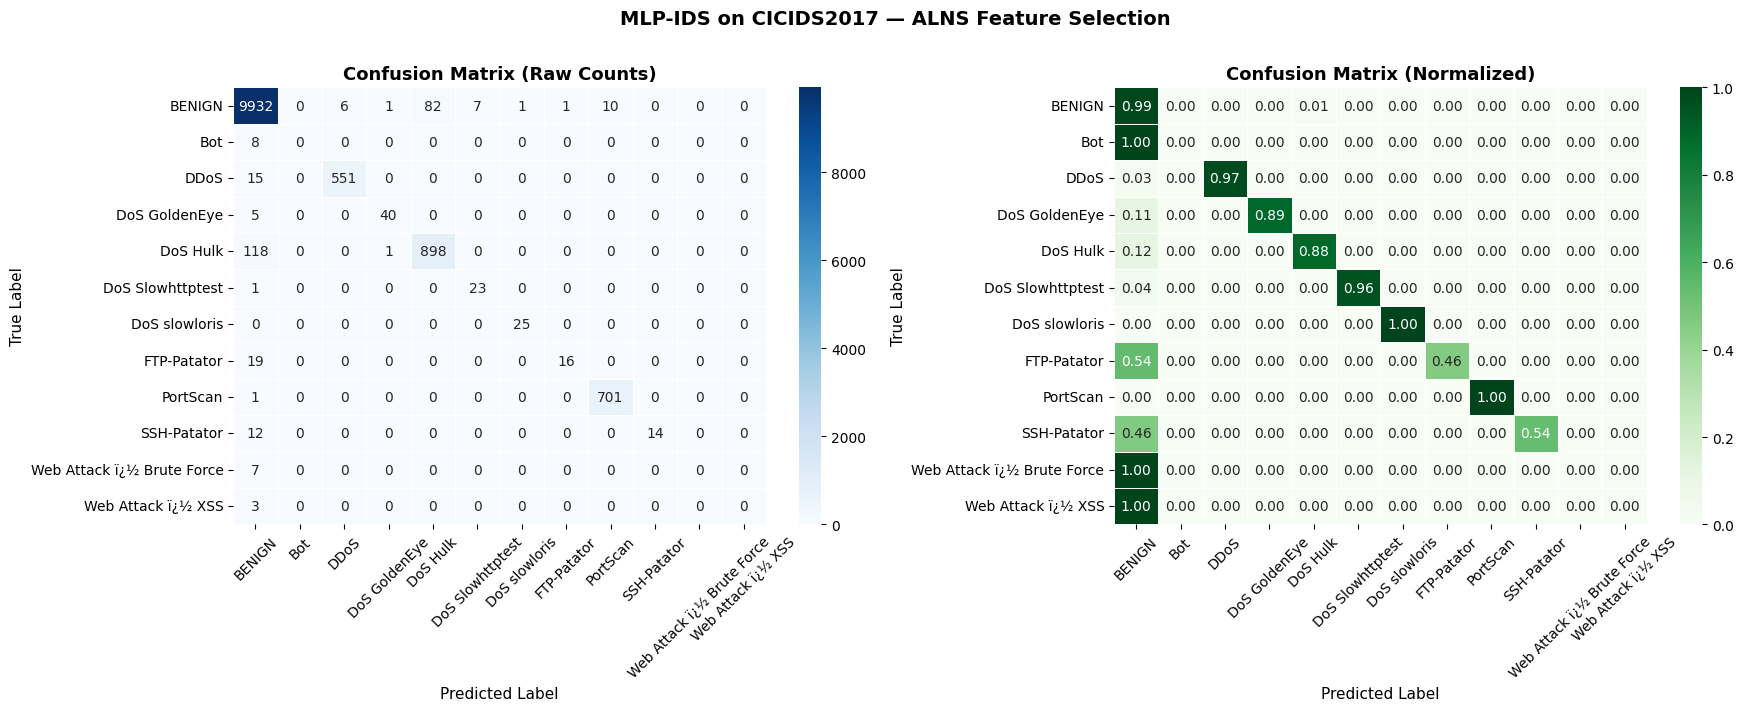

  ✓ Saved: confusion_matrix.png


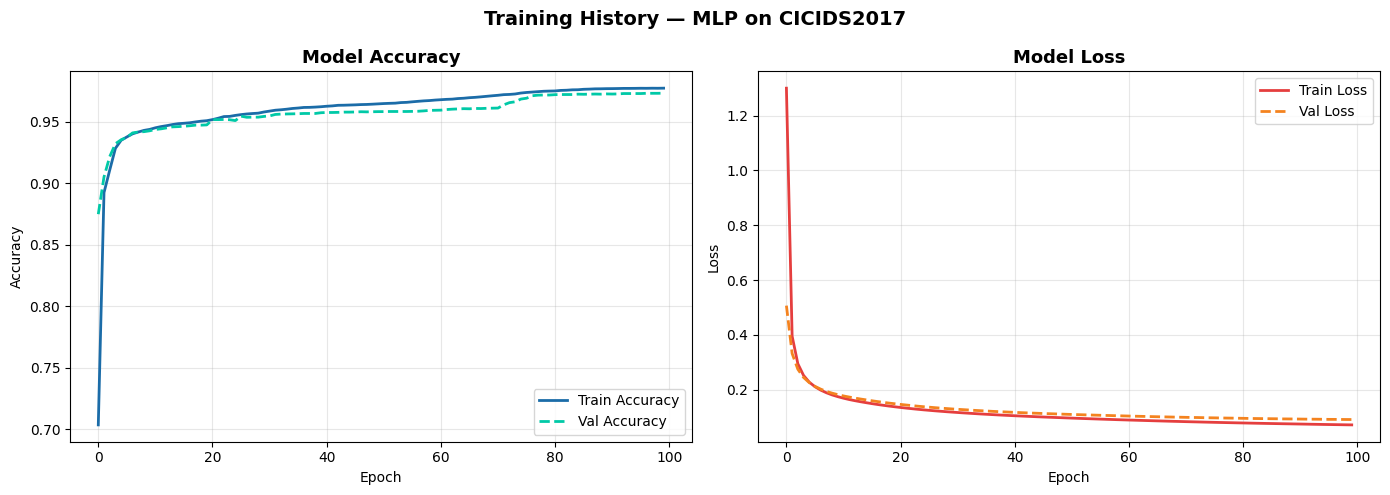

  ✓ Saved: training_history.png


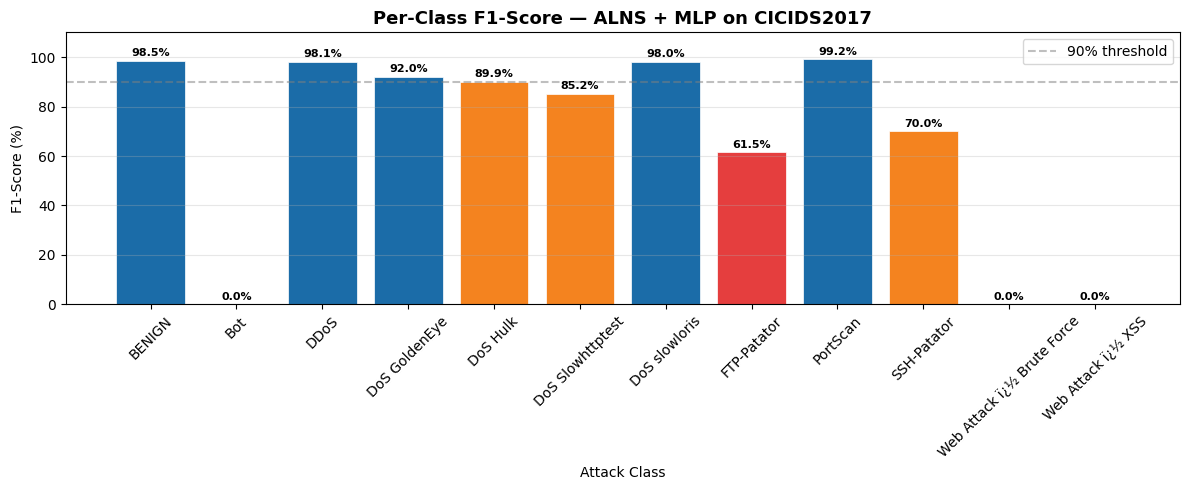

  ✓ Saved: per_class_f1.png

████████████████████████████████████████████████████████████
  FINAL SUMMARY
████████████████████████████████████████████████████████████
  Dataset          : CICIDS2017
  Feature Selection: ALNS
  Features used    : 42 / 78
  Model            : MLP (1 hidden layer, 50 neurons)
  Accuracy         : 97.62%
  Recall           : 64.06%
  Precision        : 70.79%
  F1-Score         : 66.04%

  Output files     : confusion_matrix.png
                     training_history.png
                     per_class_f1.png
████████████████████████████████████████████████████████████



In [1]:
"""
MLP-Based Intrusion Detection System
Dataset  : CICIDS2017
Method   : ALNS Feature Selection + MLP 

Paper: "MLP-Based Intrusion Detection for Securing IoT Networks"
       Cherf, Lemouari & Boulaiche (2025)


# ─────────────────────────────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────────────────────────────
import os
import time
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

# Fix random seeds for reproducibility
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# ─────────────────────────────────────────────────────────────────────────────
# CONFIG  — matches paper hyperparameters exactly
# ─────────────────────────────────────────────────────────────────────────────
LEARNING_RATE   = 0.001        # Paper Table 8
HIDDEN_LAYERS   = 1            # Paper Table 8
NEURONS_LAYER   = 50           # Paper Table 8
ACTIVATION_OUT  = "softmax"    # Paper Table 8
LOSS_FN         = "categorical_crossentropy"  # Paper Table 8
EPOCHS          = 100          # Reduced from 1000 → CPU-friendly (still good)
TRAIN_SIZE      = 0.55         # Paper Table 8
VAL_SIZE        = 0.20         # Paper Table 8
TEST_SIZE       = 0.25         # Paper Table 8
SAMPLE_SIZE     = 50000        # Max rows to load — keeps CPU fast
                               # Increase if you have time/patience

# ALNS parameters (from paper Section 3.2.3)
ALNS_MAX_ITR    = 50           # max iterations (reduced for CPU speed)
ALNS_LAMBDA     = 10           # weight update every λ iterations
SIGMA1          = 0.75         # reward: new solution is best so far
SIGMA2          = 0.50         # reward: new solution improves current
SIGMA3          = 0.25         # reward: accepted but not improvement
RHO             = 0.2          # reaction factor

# ─────────────────────────────────────────────────────────────────────────────
# STEP 1 — LOAD CICIDS2017 DATA
# ─────────────────────────────────────────────────────────────────────────────
def load_cicids2017(folder="."):
    """
    Loads all CSV files in the folder.
    CICIDS2017 comes as multiple daily CSV files.
    """
    print("\n" + "="*60)
    print("STEP 1: LOADING CICIDS2017 DATASET")
    print("="*60)

    csv_files = [f for f in os.listdir(folder)
                 if f.endswith(".csv") or f.endswith(".CSV")]

    if not csv_files:
        print("\n❌  No CSV files found in:", os.path.abspath(folder))
        print("\n    Please download CICIDS2017 from:")
        print("    https://www.unb.ca/cic/datasets/ids-2017.html")
        print("\n    Put the CSV file(s) in the SAME folder as this script.")
        print("\n    Quick start tip: Download just ONE file first, e.g.:")
        print("    'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'")
        raise FileNotFoundError("No CSV files found.")

    dfs = []
    for f in csv_files:
        path = os.path.join(folder, f)
        print(f"  Loading: {f}")
        try:
            df = pd.read_csv(path, encoding="latin-1", low_memory=False)
            dfs.append(df)
        except Exception as e:
            print(f"  ⚠ Skipped {f}: {e}")

    data = pd.concat(dfs, ignore_index=True)
    print(f"\n  ✓ Total records loaded : {len(data):,}")
    print(f"  ✓ Total features       : {data.shape[1]}")
    return data


# ─────────────────────────────────────────────────────────────────────────────
# STEP 2 — PREPROCESSING (follows paper Section 3.2)
# ─────────────────────────────────────────────────────────────────────────────
def preprocess(data, sample_size=SAMPLE_SIZE):
    print("\n" + "="*60)
    print("STEP 2: PREPROCESSING")
    print("="*60)

    # ── Clean column names (CICIDS2017 has leading spaces) ──────────────────
    data.columns = data.columns.str.strip()

    # ── Find label column ────────────────────────────────────────────────────
    label_col = None
    for col in data.columns:
        if "label" in col.lower():
            label_col = col
            break
    if label_col is None:
        raise ValueError("Could not find label column in dataset!")
    print(f"  Label column: '{label_col}'")

    # ── Replace infinity and null values (paper Section 3.2) ────────────────
    data.replace([np.inf, -np.inf], np.nan, inplace=True)
    before = len(data)
    data.dropna(inplace=True)
    print(f"  Removed {before - len(data):,} rows with null/inf values")

    # ── Sample for CPU efficiency ────────────────────────────────────────────
    if len(data) > sample_size:
        # Stratified sample to keep class balance
        data = data.groupby(label_col, group_keys=False).apply(
            lambda x: x.sample(min(len(x), max(1, int(sample_size * len(x) / len(data)))),
                                random_state=42)
        ).reset_index(drop=True)
        print(f"  Sampled to {len(data):,} rows (CPU-friendly)")

    # ── Drop classes with fewer than 10 samples (too rare to split) ─────────
    class_counts = data[label_col].value_counts()
    rare_classes = class_counts[class_counts < 10].index.tolist()
    if rare_classes:
        print(f"\n  ⚠ Dropping {len(rare_classes)} rare class(es) with <10 samples:")
        for rc in rare_classes:
            print(f"    - {rc} ({class_counts[rc]} sample(s))")
        data = data[~data[label_col].isin(rare_classes)]
        print(f"  Remaining rows: {len(data):,}")

    # ── Encode label (target) ────────────────────────────────────────────────
    le = LabelEncoder()
    y = le.fit_transform(data[label_col].astype(str))
    class_names = le.classes_
    print(f"\n  Classes found ({len(class_names)}):")
    for i, c in enumerate(class_names):
        count = np.sum(y == i)
        print(f"    [{i}] {c:<40} {count:>6} samples")

    # ── Features: drop label, keep only numeric ──────────────────────────────
    X = data.drop(columns=[label_col])
    X = X.select_dtypes(include=[np.number])
    print(f"\n  Numeric features available: {X.shape[1]}")

    # ── Z-Score Normalization (paper Section 3.2.2: Z = (X - μ) / σ) ────────
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
    print("  ✓ Z-score normalization applied")

    return X_scaled, y, class_names, le


# ─────────────────────────────────────────────────────────────────────────────
# STEP 3 — ALNS FEATURE SELECTION (paper Section 3.2.3b)
# ─────────────────────────────────────────────────────────────────────────────

def evaluate_feature_subset(X_sub, y, n_classes):
    """
    Quick evaluation: train a tiny MLP on subset, return accuracy.
    Used as the cost function C(S) for ALNS.
    Kept small (10 epochs) so ALNS runs fast on CPU.
    """
    if X_sub.shape[1] == 0:
        return 0.0

    X_tr, X_val, y_tr, y_val = train_test_split(
        X_sub, y, test_size=0.3, random_state=42, stratify=y
        if len(np.unique(y)) > 1 else None
    )

    y_tr_cat  = to_categorical(y_tr,  num_classes=n_classes)
    y_val_cat = to_categorical(y_val, num_classes=n_classes)

    model = Sequential([
        Dense(30, activation="relu", input_shape=(X_sub.shape[1],)),
        Dense(n_classes, activation="softmax")
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    model.fit(X_tr, y_tr_cat, epochs=10, batch_size=256,
              validation_data=(X_val, y_val_cat), verbose=0)

    _, acc = model.evaluate(X_val, y_val_cat, verbose=0)
    return acc


def compute_correlations(X, y):
    """Compute absolute correlation of each feature with the target."""
    corrs = []
    y_series = pd.Series(y)
    for col in X.columns:
        try:
            c = abs(X[col].corr(y_series))
        except Exception:
            c = 0.0
        corrs.append(c if not np.isnan(c) else 0.0)
    return np.array(corrs)


# ── Destroy heuristics ───────────────────────────────────────────────────────
def random_removal(solution, alpha=3):
    """Remove α random features from solution."""
    s = solution.copy()
    active = np.where(s == 1)[0]
    if len(active) <= alpha:
        return s
    to_remove = np.random.choice(active, size=min(alpha, len(active)),
                                 replace=False)
    s[to_remove] = 0
    return s

def shuffle_removal(solution):
    """Swap two random feature values."""
    s = solution.copy()
    i, j = np.random.choice(len(s), size=2, replace=False)
    s[i], s[j] = s[j], s[i]
    return s

def worst_removal(solution, correlations):
    """Remove feature with lowest correlation that is in solution."""
    s = solution.copy()
    active = np.where(s == 1)[0]
    if len(active) == 0:
        return s
    worst = active[np.argmin(correlations[active])]
    s[worst] = 0
    return s

# ── Repair heuristics ────────────────────────────────────────────────────────
def random_insertion(solution):
    """Add a random excluded feature back."""
    s = solution.copy()
    inactive = np.where(s == 0)[0]
    if len(inactive) == 0:
        return s
    s[np.random.choice(inactive)] = 1
    return s

def greedy_insertion(solution, correlations):
    """Add the excluded feature with highest correlation."""
    s = solution.copy()
    inactive = np.where(s == 0)[0]
    if len(inactive) == 0:
        return s
    best = inactive[np.argmax(correlations[inactive])]
    s[best] = 1
    return s

# ── Acceptance methods ───────────────────────────────────────────────────────
def sa_accept(current_score, new_score, temperature):
    if new_score > current_score:
        return True
    delta = new_score - current_score
    prob = np.exp(delta / max(temperature, 1e-10))
    return random.random() < prob

def greedy_accept(current_score, new_score):
    return new_score > current_score


# ── Main ALNS loop ───────────────────────────────────────────────────────────
def alns_feature_selection(X, y, n_classes, max_itr=ALNS_MAX_ITR,
                            lam=ALNS_LAMBDA):
    print("\n" + "="*60)
    print("STEP 3: ALNS FEATURE SELECTION")
    print("="*60)
    print(f"  Total features : {X.shape[1]}")
    print(f"  Max iterations : {max_itr}")
    print(f"  Weight update  : every {lam} iterations")
    print(f"  (This may take a few minutes on CPU — please wait...)\n")

    n_features   = X.shape[1]
    correlations = compute_correlations(X, y)

    # ── Name the heuristic sets ──────────────────────────────────────────────
    destroy_names = ["random_removal", "shuffle_removal", "worst_removal"]
    repair_names  = ["random_insertion", "greedy_insertion"]

    # ── Weights (start equal) ────────────────────────────────────────────────
    d_weights = np.ones(len(destroy_names))
    r_weights = np.ones(len(repair_names))

    # ── Tracking scores for weight update ───────────────────────────────────
    d_score  = np.zeros(len(destroy_names))
    r_score  = np.zeros(len(repair_names))
    d_used   = np.zeros(len(destroy_names))
    r_used   = np.zeros(len(repair_names))

    # ── Initial solution: random boolean vector ──────────────────────────────
    S = np.random.randint(0, 2, n_features)
    if S.sum() == 0:
        S[np.random.randint(n_features)] = 1  # at least 1 feature

    X_s = X.iloc[:, S == 1]
    current_score = evaluate_feature_subset(X_s.values, y, n_classes)
    best_score    = current_score
    best_solution = S.copy()

    temperature = 100.0  # SA acceptance temperature

    print(f"  Initial random subset: {S.sum()} features, "
          f"accuracy={current_score:.4f}")

    for itr in range(max_itr):
        # ── Select destroy/repair by probability ─────────────────────────────
        d_probs = d_weights / d_weights.sum()
        r_probs = r_weights / r_weights.sum()
        d_idx   = np.random.choice(len(destroy_names), p=d_probs)
        r_idx   = np.random.choice(len(repair_names),  p=r_probs)

        # ── Apply destroy ────────────────────────────────────────────────────
        if d_idx == 0:
            S_new = random_removal(S)
        elif d_idx == 1:
            S_new = shuffle_removal(S)
        else:
            S_new = worst_removal(S, correlations)

        # ── Apply repair ─────────────────────────────────────────────────────
        if r_idx == 0:
            S_new = random_insertion(S_new)
        else:
            S_new = greedy_insertion(S_new, correlations)

        # ── Ensure at least 1 feature selected ──────────────────────────────
        if S_new.sum() == 0:
            S_new[np.random.randint(n_features)] = 1

        # ── Evaluate new solution ────────────────────────────────────────────
        X_new    = X.iloc[:, S_new == 1]
        new_score = evaluate_feature_subset(X_new.values, y, n_classes)

        # ── Track usage ──────────────────────────────────────────────────────
        d_used[d_idx] += 1
        r_used[r_idx] += 1

        # ── Acceptance (SA-style) ────────────────────────────────────────────
        accepted = sa_accept(current_score, new_score, temperature)

        if accepted:
            S             = S_new.copy()
            current_score = new_score

            # Reward heuristics
            if new_score > best_score:
                # Best solution found so far
                best_score    = new_score
                best_solution = S_new.copy()
                d_score[d_idx] += SIGMA1
                r_score[r_idx] += SIGMA1
            elif new_score > current_score:
                # Improves current
                d_score[d_idx] += SIGMA2
                r_score[r_idx] += SIGMA2
            else:
                # Accepted but not improvement
                d_score[d_idx] += SIGMA3
                r_score[r_idx] += SIGMA3

        temperature *= 0.99  # cool down

        # ── Weight update every λ iterations (paper formula) ─────────────────
        if (itr + 1) % lam == 0:
            for i in range(len(destroy_names)):
                p = d_weights[i] / d_weights.sum()
                if d_used[i] > 0:
                    d_weights[i] = (1 - p) * d_weights[i] + \
                                    RHO * (d_score[i] / d_used[i])
                else:
                    d_weights[i] = (1 - p) * d_weights[i]

            for i in range(len(repair_names)):
                p = r_weights[i] / r_weights.sum()
                if r_used[i] > 0:
                    r_weights[i] = (1 - p) * r_weights[i] + \
                                    RHO * (r_score[i] / r_used[i])
                else:
                    r_weights[i] = (1 - p) * r_weights[i]

            # Reset trackers
            d_score[:] = 0
            r_score[:] = 0
            d_used[:]  = 0
            r_used[:]  = 0

        # ── Progress print ───────────────────────────────────────────────────
        print(f"  Iter {itr+1:>3}/{max_itr} | "
              f"Features: {S.sum():>2} | "
              f"Current: {current_score:.4f} | "
              f"Best: {best_score:.4f}")

    selected_features = X.columns[best_solution == 1].tolist()
    print(f"\n  ✓ ALNS done!")
    print(f"  ✓ Selected {len(selected_features)} of "
          f"{n_features} features")
    print(f"  ✓ Best validation accuracy during search: {best_score:.4f}")
    print(f"\n  Selected features:")
    for i, f in enumerate(selected_features, 1):
        print(f"    {i:>2}. {f}")

    return selected_features, best_score


# ─────────────────────────────────────────────────────────────────────────────
# STEP 4 — TRAIN FINAL MLP (paper hyperparameters exactly)
# ─────────────────────────────────────────────────────────────────────────────
def build_mlp(input_dim, n_classes):
    """
    MLP as described in paper:
    - 1 hidden layer, 50 neurons
    - Softmax output
    - Categorical cross-entropy loss
    - Adam optimizer, lr=0.001
    """
    model = Sequential([
        Dense(NEURONS_LAYER, activation="relu",
              input_shape=(input_dim,),
              name="hidden_layer_1"),
        Dense(n_classes, activation=ACTIVATION_OUT,
              name="output_layer")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=LOSS_FN,
        metrics=["accuracy"]
    )
    return model


def train_model(X_train, X_val, y_train, y_val, n_classes):
    print("\n" + "="*60)
    print("STEP 4: TRAINING FINAL MLP")
    print("="*60)
    print(f"  Architecture : Input({X_train.shape[1]}) → "
          f"Dense({NEURONS_LAYER}, ReLU) → "
          f"Dense({n_classes}, Softmax)")
    print(f"  Loss         : {LOSS_FN}")
    print(f"  Learning rate: {LEARNING_RATE}")
    print(f"  Epochs       : {EPOCHS} (with early stopping)")
    print(f"  Train samples: {len(X_train):,}")
    print(f"  Val samples  : {len(X_val):,}\n")

    y_train_cat = to_categorical(y_train, num_classes=n_classes)
    y_val_cat   = to_categorical(y_val,   num_classes=n_classes)

    model = build_mlp(X_train.shape[1], n_classes)
    model.summary()

    # Early stopping — stops if val_loss doesn't improve for 15 epochs
    early_stop = EarlyStopping(monitor="val_loss", patience=15,
                               restore_best_weights=True, verbose=1)

    start = time.time()
    history = model.fit(
        X_train, y_train_cat,
        validation_data=(X_val, y_val_cat),
        epochs=EPOCHS,
        batch_size=256,           # larger batch = faster on CPU
        callbacks=[early_stop],
        verbose=1
    )
    elapsed = time.time() - start
    print(f"\n  ✓ Training done in {elapsed:.1f}s")
    return model, history


# ─────────────────────────────────────────────────────────────────────────────
# STEP 5 — EVALUATE (paper Section 3.4 metrics)
# ─────────────────────────────────────────────────────────────────────────────
def evaluate_model(model, X_test, y_test, class_names, n_classes):
    print("\n" + "="*60)
    print("STEP 5: EVALUATION")
    print("="*60)

    y_test_cat = to_categorical(y_test, num_classes=n_classes)
    y_pred_probs = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # ── Metrics (paper Section 3.4) ──────────────────────────────────────────
    acc  = accuracy_score(y_test, y_pred) * 100
    rec  = recall_score(y_test, y_pred, average="macro",
                        zero_division=0) * 100
    prec = precision_score(y_test, y_pred, average="macro",
                           zero_division=0) * 100
    f1   = f1_score(y_test, y_pred, average="macro",
                    zero_division=0) * 100

    print(f"\n  ┌─────────────────────────────────────┐")
    print(f"  │         FINAL RESULTS                │")
    print(f"  ├─────────────────────────────────────┤")
    print(f"  │  Accuracy  : {acc:>7.2f}%              │")
    print(f"  │  Recall    : {rec:>7.2f}%              │")
    print(f"  │  Precision : {prec:>7.2f}%              │")
    print(f"  │  F1-Score  : {f1:>7.2f}%              │")
    print(f"  └─────────────────────────────────────┘")

    print(f"\n  Paper target (ALNS on CICIDS2017):")
    print(f"    Accuracy  : 99.80%")
    print(f"    Recall    : 99.79%")
    print(f"    Precision : 99.80%")
    print(f"    F1-Score  : 99.79%")
    print(f"\n  Note: Difference from paper is expected —")
    print(f"  paper used full dataset. We sampled {SAMPLE_SIZE:,} rows for CPU.")

    # ── Per-class report ─────────────────────────────────────────────────────
    print(f"\n  Per-Class Report:")
    print("  " + "-"*60)
    print(classification_report(y_test, y_pred,
                                target_names=class_names,
                                zero_division=0))

    return y_pred, acc, rec, prec, f1


# ─────────────────────────────────────────────────────────────────────────────
# STEP 6 — PLOTS
# ─────────────────────────────────────────────────────────────────────────────
def plot_confusion_matrix(y_test, y_pred, class_names):
    cm = confusion_matrix(y_test, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    # Raw counts
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names,
                ax=axes[0], linewidths=0.5)
    axes[0].set_title("Confusion Matrix (Raw Counts)", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Predicted Label", fontsize=11)
    axes[0].set_ylabel("True Label", fontsize=11)
    axes[0].tick_params(axis="x", rotation=45)
    axes[0].tick_params(axis="y", rotation=0)

    # Normalized
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens",
                xticklabels=class_names,
                yticklabels=class_names,
                ax=axes[1], linewidths=0.5,
                vmin=0, vmax=1)
    axes[1].set_title("Confusion Matrix (Normalized)", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Predicted Label", fontsize=11)
    axes[1].set_ylabel("True Label", fontsize=11)
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].tick_params(axis="y", rotation=0)

    plt.suptitle("MLP-IDS on CICIDS2017 — ALNS Feature Selection",
                 fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("  ✓ Saved: confusion_matrix.png")


def plot_training_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy
    axes[0].plot(history.history["accuracy"],
                 label="Train Accuracy", color="#1B6CA8", linewidth=2)
    axes[0].plot(history.history["val_accuracy"],
                 label="Val Accuracy", color="#00C9A7",
                 linewidth=2, linestyle="--")
    axes[0].set_title("Model Accuracy", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss
    axes[1].plot(history.history["loss"],
                 label="Train Loss", color="#E53E3E", linewidth=2)
    axes[1].plot(history.history["val_loss"],
                 label="Val Loss", color="#F4831F",
                 linewidth=2, linestyle="--")
    axes[1].set_title("Model Loss", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.suptitle("Training History — MLP on CICIDS2017",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("training_history.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("  ✓ Saved: training_history.png")


def plot_metrics_bar(class_names, y_test, y_pred):
    """Per-class F1 bar chart."""
    f1_per_class = f1_score(y_test, y_pred, average=None,
                            zero_division=0) * 100

    fig, ax = plt.subplots(figsize=(12, 5))
    colors = ["#1B6CA8" if v >= 90 else "#F4831F" if v >= 70
              else "#E53E3E" for v in f1_per_class]
    bars = ax.bar(class_names, f1_per_class, color=colors,
                  edgecolor="white", linewidth=0.5)

    ax.set_ylim(0, 110)
    ax.set_title("Per-Class F1-Score — ALNS + MLP on CICIDS2017",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Attack Class")
    ax.set_ylabel("F1-Score (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.axhline(y=90, color="gray", linestyle="--", alpha=0.5,
               label="90% threshold")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    for bar, val in zip(bars, f1_per_class):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f"{val:.1f}%", ha="center", va="bottom",
                fontsize=8, fontweight="bold")

    plt.tight_layout()
    plt.savefig("per_class_f1.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("  ✓ Saved: per_class_f1.png")


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────
def main():
    print("\n" + "█"*60)
    print("  MLP-BASED INTRUSION DETECTION — CICIDS2017")
    print("  Following: Cherf, Lemouari & Boulaiche (2025)")
    print("█"*60)

    # ── 1. Load ───────────────────────────────────────────────────────────────
    data = load_cicids2017(folder=".")

    # ── 2. Preprocess ─────────────────────────────────────────────────────────
    X, y, class_names, le = preprocess(data, sample_size=SAMPLE_SIZE)
    n_classes = len(class_names)

    # ── 3. Train/Val/Test split (55/20/25 as per paper) ──────────────────────
    print("\n" + "="*60)
    print("TRAIN / VAL / TEST SPLIT (55 / 20 / 25)")
    print("="*60)

    # Stratify only if every class has >=2 samples
    use_stratify = (pd.Series(y).value_counts().min() >= 2)

    # First split off test (25%)
    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=42,
        stratify=y if use_stratify else None
    )
    # Then split train (55%) and val (20%) from remaining 75%
    use_stratify2 = (pd.Series(y_trainval).value_counts().min() >= 2)
    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval,
        test_size=(VAL_SIZE / (TRAIN_SIZE + VAL_SIZE)),
        random_state=42,
        stratify=y_trainval if use_stratify2 else None
    )
    print(f"  Train : {len(X_train):>6,} samples ({TRAIN_SIZE*100:.0f}%)")
    print(f"  Val   : {len(X_val):>6,} samples ({VAL_SIZE*100:.0f}%)")
    print(f"  Test  : {len(X_test):>6,} samples ({TEST_SIZE*100:.0f}%)")

    # ── 4. ALNS Feature Selection ─────────────────────────────────────────────
    # Run ALNS on training data only (to avoid data leakage)
    selected_features, alns_best_acc = alns_feature_selection(
        X_train, y_train, n_classes
    )

    # Apply selected features to all splits
    X_train_sel = X_train[selected_features].values
    X_val_sel   = X_val[selected_features].values
    X_test_sel  = X_test[selected_features].values

    print(f"\n  Features before ALNS : {X.shape[1]}")
    print(f"  Features after  ALNS : {len(selected_features)}")

    # ── 5. Train final MLP ────────────────────────────────────────────────────
    model, history = train_model(
        X_train_sel, X_val_sel, y_train, y_val, n_classes
    )

    # ── 6. Evaluate on test set ───────────────────────────────────────────────
    y_pred, acc, rec, prec, f1 = evaluate_model(
        model, X_test_sel, y_test, class_names, n_classes
    )

    # ── 7. Plots ──────────────────────────────────────────────────────────────
    print("\n" + "="*60)
    print("STEP 6: GENERATING PLOTS")
    print("="*60)
    plot_confusion_matrix(y_test, y_pred, class_names)
    plot_training_history(history)
    plot_metrics_bar(class_names, y_test, y_pred)

    # ── 8. Summary ────────────────────────────────────────────────────────────
    print("\n" + "█"*60)
    print("  FINAL SUMMARY")
    print("█"*60)
    print(f"  Dataset          : CICIDS2017")
    print(f"  Feature Selection: ALNS")
    print(f"  Features used    : {len(selected_features)} / {X.shape[1]}")
    print(f"  Model            : MLP (1 hidden layer, 50 neurons)")
    print(f"  Accuracy         : {acc:.2f}%")
    print(f"  Recall           : {rec:.2f}%")
    print(f"  Precision        : {prec:.2f}%")
    print(f"  F1-Score         : {f1:.2f}%")
    print(f"\n  Output files     : confusion_matrix.png")
    print(f"                     training_history.png")
    print(f"                     per_class_f1.png")
    print("█"*60 + "\n")


if __name__ == "__main__":
    main()